# 07 · URL-only models without the shortcuts

Notebook 06 showed that every legitimate URL is a bare `https://www.<domain>` homepage. A URL-only model can score 99.7% just by noticing *how the URL starts* and *whether it has a path*.

Here we retrain the same URL-only models on three **views** of each URL (`phishguard.urls.URL_VIEWS`), each removing more of the shortcut:

| View | `https://www.paypal-secure.top/login?id=7` becomes | Removes |
|---|---|---|
| **raw URL** | `https://www.paypal-secure.top/login?id=7` | nothing (Milestone 2 setting) |
| **no scheme/www** | `paypal-secure.top/login?id=7` | the `https://www.` prefix |
| **domain only** | `paypal-secure.top` | the prefix, the path and the query |

The **domain-only** score is the honest one. It asks: *can the model tell a phishing domain from a legitimate one by its name?*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET
from phishguard.split import get_splits
from phishguard.urls import URL_VIEWS
from phishguard.features import extract_features
from phishguard.modeling import param_grid, tune, fit_and_test
from phishguard.evaluate import save_result

df = load_clean()
splits = get_splits(df)
train_idx, val_idx, test_idx = splits
y = df[TARGET]

example = pd.Series(["https://www.paypal-secure.top/login?id=7", "https://www.wikipedia.org"])
pd.DataFrame({name: view(example) for name, view in URL_VIEWS.items()})

,raw URL,no scheme/www,domain only
0,https://www.paypal-secure.top/login?id=7,paypal-secure.top/login?id=7,paypal-secure.top
1,https://www.wikipedia.org,wikipedia.org,wikipedia.org


## Train both URL-only models on every view

Same models as in Milestone 2:
- **Char n-gram + Logistic Regression.** `C` is re-tuned on validation for each view, because the best regularisation can change when the input changes.
- **XGBoost on the 39 URL features**, with the Milestone 2 settings.

In [2]:
def make_ngram(C):
    return make_pipeline(
        TfidfVectorizer(analyzer="char", ngram_range=(1, 4), min_df=2, sublinear_tf=True, dtype=np.float32),
        LogisticRegression(C=C, solver="liblinear", max_iter=3000),
    )

rows, models = [], {}
for view_name, view in URL_VIEWS.items():
    urls = view(df["URL"])

    _, best = tune(make_ngram, param_grid(C=[1.0, 3.0, 10.0]), urls, y, splits)
    ngram, t, m = fit_and_test(make_ngram(**best), urls, y, splits)
    save_result(f"Char n-gram LogReg | {view_name}", view_name, t, m, group="m3_views")
    rows.append({"view": view_name, "model": "Char n-gram LogReg", **m})
    models[view_name] = ngram

    features = extract_features(urls)
    xgb = XGBClassifier(max_depth=10, n_estimators=800, learning_rate=0.1, n_jobs=-1, random_state=42)
    _, t, m = fit_and_test(xgb, features, y, splits)
    save_result(f"XGBoost URL features | {view_name}", view_name, t, m, group="m3_views")
    rows.append({"view": view_name, "model": "XGBoost (URL features)", **m})

results = pd.DataFrame(rows)
results[["view", "model", "accuracy", "precision", "recall", "f1", "roc_auc"]].round(4)

,view,model,accuracy,precision,recall,f1,roc_auc
0,raw URL,Char n-gram LogReg,0.9970,0.9988,0.9940,0.9964,0.9987
1,raw URL,XGBoost (URL features),0.9968,0.9995,0.9929,0.9962,0.9971
2,no scheme/www,Char n-gram LogReg,0.9089,0.9607,0.8188,0.8841,0.9489
3,no scheme/www,XGBoost (URL features),0.8797,0.9535,0.7532,0.8416,0.9056
4,domain only,Char n-gram LogReg,0.8859,0.9407,0.7804,0.8531,0.9310
5,domain only,XGBoost (URL features),0.8142,0.9333,0.6054,0.7344,0.8548


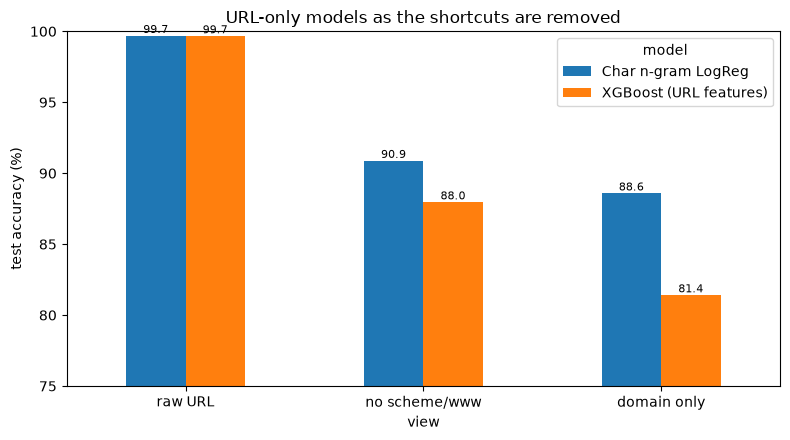

In [3]:
pivot = results.pivot(index="view", columns="model", values="accuracy").loc[list(URL_VIEWS)] * 100
ax = pivot.plot.bar(figsize=(8, 4.5), rot=0)
ax.set_ylim(75, 100)
ax.set_ylabel("test accuracy (%)")
ax.set_title("URL-only models as the shortcuts are removed")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8)
plt.tight_layout()
plt.show()

## What does the domain-only model look at?

With the prefix and path gone, the n-gram weights should show real signals: cheap TLDs, brand names inside other domains, and so on.

In [4]:
vectorizer, logreg = models["domain only"].named_steps.values()
weights = pd.Series(logreg.coef_[0], index=vectorizer.get_feature_names_out())
pd.DataFrame({
    "→ phishing": weights.nlargest(25).index, "w": weights.nlargest(25).round(1).values,
    "→ legitimate": weights.nsmallest(25).index, "w ": weights.nsmallest(25).round(1).values,
})

,→ phishing,w,→ legitimate,w
0,.cf,14.1,.gov,-10.0
1,.ga,11.5,.go,-9.9
2,.ml,11.1,.jp,-8.8
3,.w,11.0,.edu,-8.5
4,3,9.8,.ed,-7.6
5,x,9.7,.de,-7.0
6,.top,9.7,.it,-7.0
7,6,9.6,.com,-7.0
8,-,9.4,.ie,-6.7
9,8,8.8,.cz,-6.4


In [5]:
domains = URL_VIEWS["domain only"](df["URL"])
val_prob = pd.Series(models["domain only"].predict_proba(domains.loc[val_idx])[:, 1], index=val_idx)
pd.DataFrame({
    "caught phishing (highest score)": domains.loc[val_prob[y.loc[val_idx] == 1].nlargest(8).index].values,
    "missed phishing (lowest score)": domains.loc[val_prob[y.loc[val_idx] == 1].nsmallest(8).index].values,
    "legit flagged as phishing": domains.loc[val_prob[y.loc[val_idx] == 0].nlargest(8).index].values,
})

,caught phishing (highest score),missed phishing (lowest score),legit flagged as phishing
0,175908c6-f7d3-4d92-8062-cc52cc4c81f6.id.repl.co,cama.it,iatuc0e2xz.ga
1,64a04e77-70c5-455d-8c43-c028ff5c8323.id.repl.co,vistavineyard.co.uk,wwwxxx.club
2,559fcc05-76e6-4af8-a389-f841df00fb74.id.repl.co,ohe.ie,dns.com
3,5da2f740-dbcc-47f5-8956-ab11e61b1367.id.repl.co,sen.org.nz,nsupdate.info
4,xn--w1ai.web.app,golfcast.jp,ostan-mz.ir
5,bafybeicx2gtlbxxgyfw323iah63y4u433dy5q6lwipduo...,golfcast.jp,bolstr.xyz
6,1e8c076d-095d-453d-adf1-c64963f0dfa3.id.repl.co,artas.org,joycasino0kz.xyz
7,bafybeig2bz7enuyqhnj5aifld5iwt4k674lvmjeuuxosu...,inboundmag.com,radix.website


**Reading the tables:**
- **Real phishing signals** now dominate the weights: free or cheap TLDs (`.cf`, `.ga`, `.ml`, `.top`), digits and hyphens in the name, and random-looking subdomains on free hosting (`repl.co`, IPFS gateways). Legitimate signals are institutional TLDs (`.gov`, `.edu`, `.ac.`) and country TLDs.
- **Missed phishing** look like ordinary small-business sites (`cama.it`, `vistavineyard.co.uk`). These are probably *compromised* legitimate sites, which no URL-only model can recognise from the name.
- **False alarms** are legitimate sites with phishing-like names (`iatuc0e2xz.ga`, `wwwxxx.club`).

## What we learned

| View | Char n-gram | XGBoost (features) |
|---|---|---|
| raw URL | 99.7% | 99.7% |
| no scheme/www | 90.9% | 88.0% |
| domain only | 88.6% | 81.4% |

1. **About 10 points of URL-only accuracy come from the `https://www.` prefix and from "has a path".** These describe how PhiUSIIL was collected (legitimate = homepages), not phishing.
2. **The honest URL-only score is about 88%,** from the domain name alone. That's still far above chance (57.6% by always guessing "legitimate"), so the domain name carries real signal.
3. **Character n-grams beat hand-written features once the shortcuts are gone** (88.6% vs 81.4%). The useful information sits in the characters of the name (TLDs, brand words, odd spellings), which our counts don't capture. That's the motivation for the character-level CNN and BiLSTM in Milestone 4.

**Decision D10:** from now on, every URL model is reported on **raw URL** (comparable to published work) **and** **domain only** (the honest number).